# 00 - MNIST-784 Dataset Exploration
## Objective

Explore the MNIST handwritten digit dataset obtained from OpenML.

Steps:

1. Dataset acquisition from OpenML.
2. Target distribution analysis.
3. Digit visualization.
4. Two-dimensional UMAP visualization on the raw 784 pixels.

All pixel intensities are scaled to [0, 1].

## Imports

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import umap

from mnist_rbf import load_mnist, save_figure

/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Dataset Acquisition

In [2]:
X, y = load_mnist(scale=True, dtype=np.float32)

print("X:", X.shape, X.dtype, f"range [{X.min():.1f}, {X.max():.1f}]")
print("y:", y.shape, y.dtype)

Loading MNIST from local storage.
X: (70000, 784) float32 range [0.0, 1.0]
y: (70000,) uint8


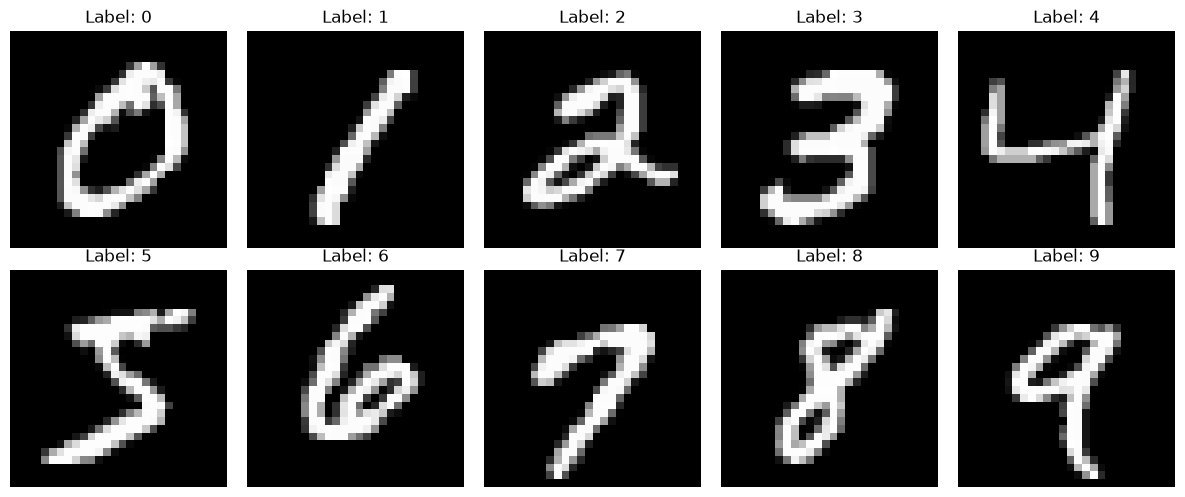

In [3]:
# First example of each digit (index of first occurrence per label)

digits, first_idx = np.unique(y, return_index=True)

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for ax, digit, idx in zip(axes.flat, digits, first_idx):
    ax.imshow(X[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.tight_layout()
plt.show()

## Target Distribution

Explore the number of observations for each digit.

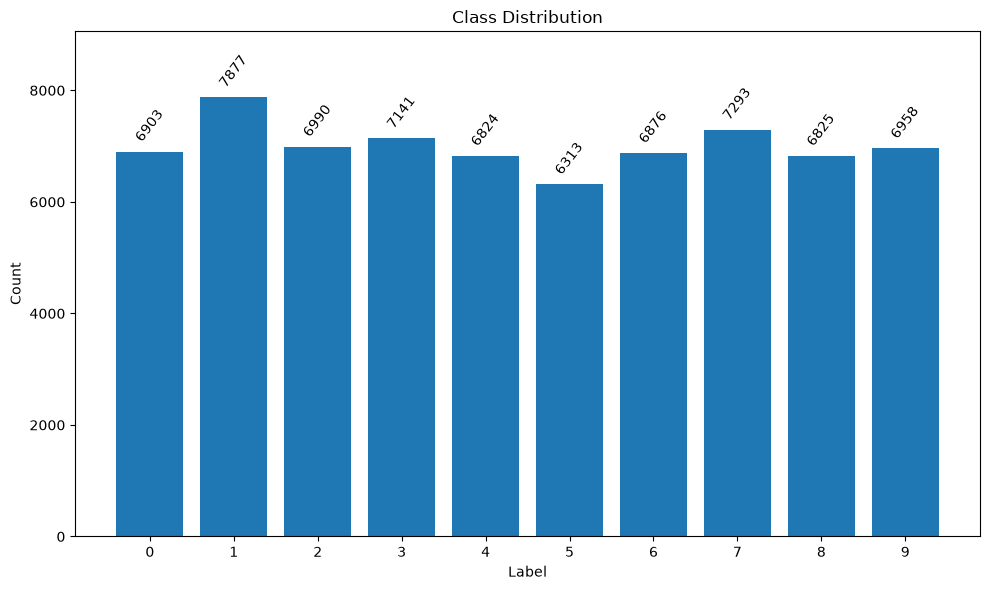

In [4]:
labels = np.arange(10)
counts = np.bincount(y, minlength=10)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(labels, counts)

for bar, count in zip(bars, counts):
    ax.annotate(
        str(count),
        xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        rotation=52.5,
        fontsize=10
    )

ax.set_xticks(labels)
ax.set_xlabel("Label")
ax.set_ylabel("Count")
ax.set_title("Class Distribution")
ax.margins(y=0.15)

plt.tight_layout()

save_figure(fig, "class-distribution.png")

plt.show()

## Digit Visualization

### Random Samples

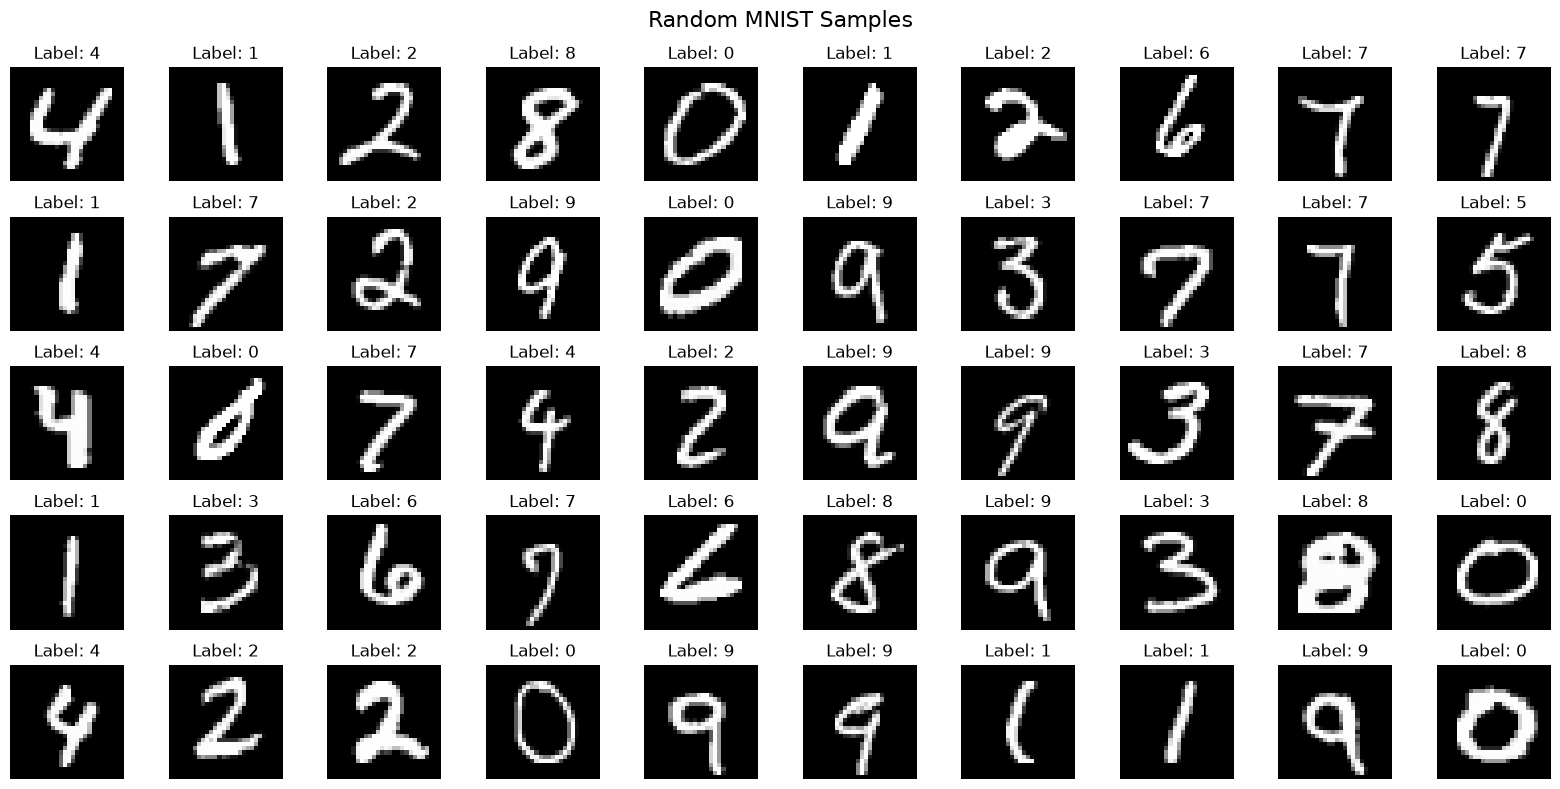

In [5]:
n_samples = 50
n_cols = 10

rng = np.random.default_rng(42)
sample_idx = rng.choice(len(y), size=n_samples, replace=False)

fig, axes = plt.subplots(
    n_samples // n_cols,
    n_cols,
    figsize=(16, 8),
)

for ax, idx in zip(axes.flat, sample_idx):
    ax.imshow(X[idx].reshape(28, 28), cmap="gray")
    ax.set_title(f"Label: {y[idx]}")
    ax.axis("off")

plt.suptitle("Random MNIST Samples", fontsize=16)
plt.tight_layout()

save_figure(fig, "random-mnist-samples.png")

plt.show()

### Average image per digit

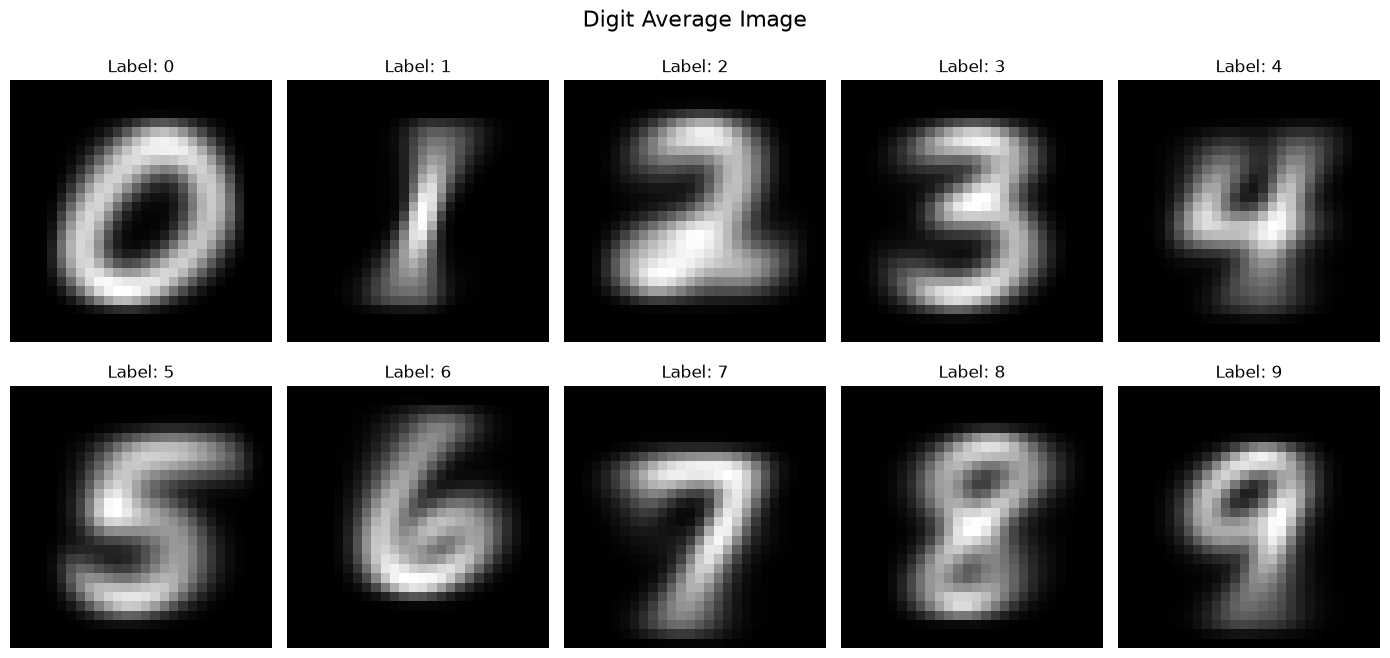

In [10]:
fig, axes = plt.subplots(
    2,
    5,
    figsize=(14, 7),
)

for digit, ax in zip(range(10), axes.flat):
    mean_image = X[y == digit].mean(axis=0).reshape(28, 28)

    ax.imshow(mean_image, cmap="gray")
    ax.set_title(f"Label: {digit}")
    ax.axis("off")

plt.suptitle("Digit Average Image", fontsize=16)
plt.tight_layout()

save_figure(fig, "digit-average-images.png")

plt.show()

## Raw Pixel UMAP Visualization

Project the original 784-dimensional pixel representation directly into two dimensions using UMAP. Pixel intensities are scaled to [0, 1].


In [7]:
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42,
    low_memory=True,
    verbose=True,
)

# Fit directly on all 784 raw pixel features.
X_umap = umap_model.fit_transform(X)

print("UMAP embedding shape:", X_umap.shape)

/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/home/cudi/projects/mnist-rbf/.venv/lib/python3.13/site-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP(n_jobs=1, random_state=42, verbose=True)
Tue Nov 24 17:17:36 2026 Construct fuzzy simplicial set
Tue Nov 24 17:17:36 2026 Finding Nearest Neighbors
Tue Nov 24 17:17:36 2026 Using PyNNDescent with 0.5.x settings to find nearest neighbors (RINND not used: RINND >= 0.3.1 is not installed)
Tue Nov 24 17:17:36 2026 Building RP forest with 18 trees
Tue Nov 24 17:17:38 2026 NN descent for 16 iterations
	 1  /  16
	 2  /  16
	 3  /  16
	Stopping threshold met -- exiting after 3 iterations
Tue Nov 24 17:18:07 2026 Finished Nearest Neighbor Search
Tue Nov 24 17:18:11 2026 Construct embedding
Tue Nov 24 17:18:11 2026 Checking components for spectral layout...
Tue Nov 24 17:18:11 2026 Computing Laplacian...
Tue Nov 24 17:18:11 2026 Computing Eigenvectors...
Tue Nov 24 17:18:15 2026 Eigenvectors computed, ordering them...


Epochs completed: 100%| ██████████ 200/200 [00:24]


Tue Nov 24 17:18:40 2026 Finished embedding
UMAP embedding shape: (70000, 2)


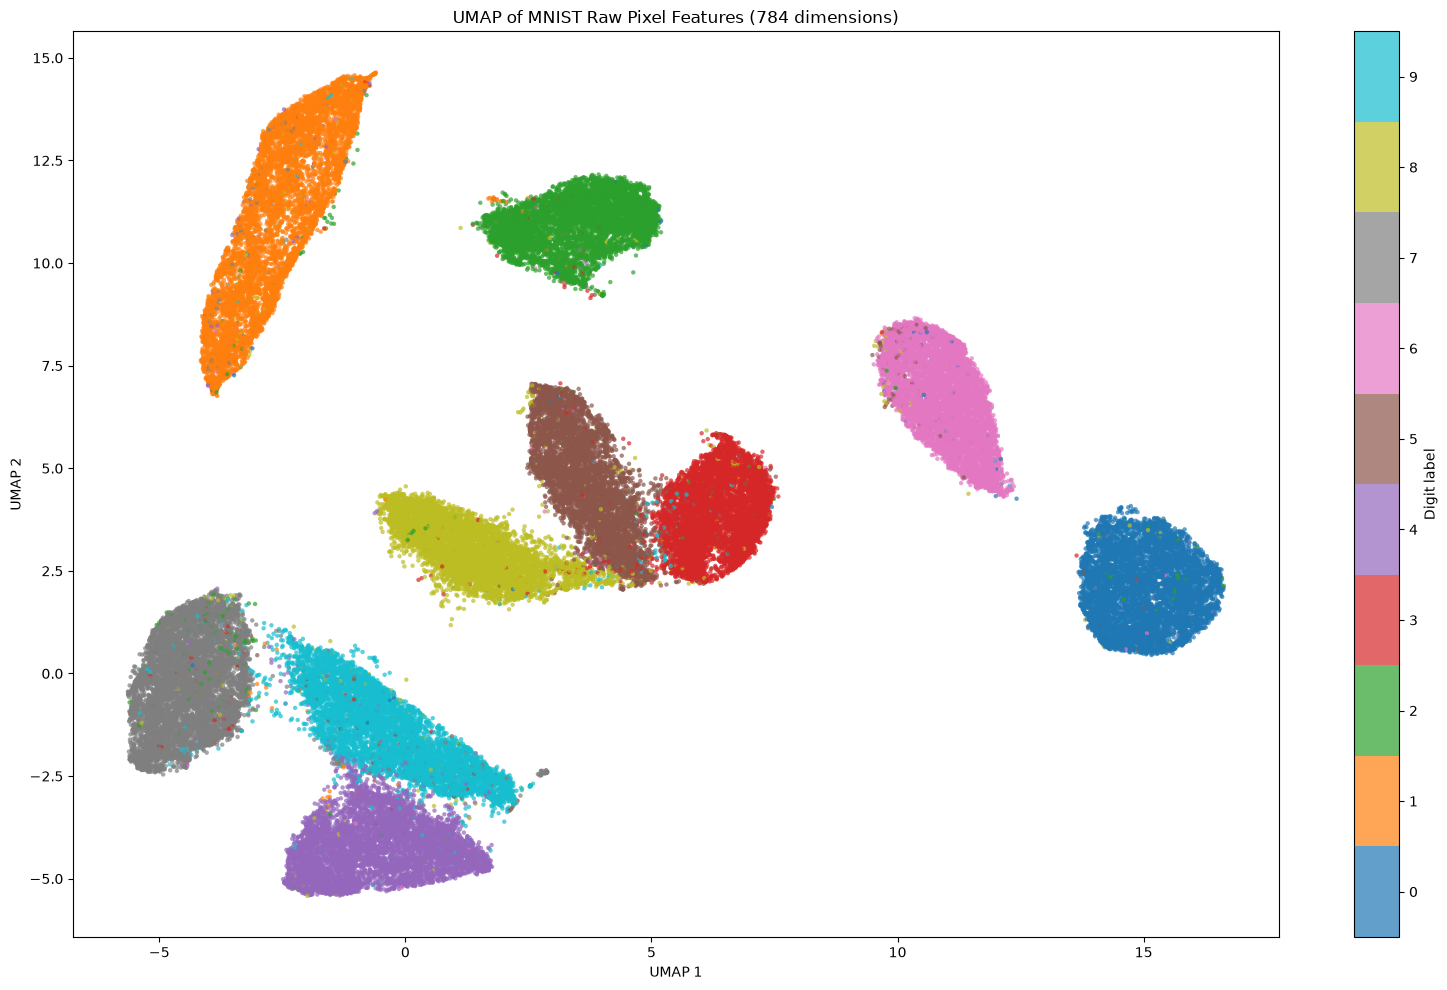

In [8]:
fig, ax = plt.subplots(figsize=(16, 10))

scatter = ax.scatter(
    X_umap[:, 0],
    X_umap[:, 1],
    c=y,
    cmap="tab10",
    norm=plt.Normalize(-0.5, 9.5),
    s=10,
    alpha=0.70,
    linewidths=0,
    rasterized=True,
)

colorbar = fig.colorbar(
    scatter,
    ax=ax,
    ticks=np.arange(10),
)
colorbar.set_label("Digit label")

ax.set_xlabel("UMAP 1")
ax.set_ylabel("UMAP 2")
ax.set_title("UMAP of MNIST Raw Pixel Features (784 dimensions)")

fig.tight_layout()
save_figure(fig, "mnist-raw-pixels-umap.png")
plt.show()